# Task4 — Curriculum corruption + frozen teacher distillation

**Run All: 5 folds × 6 epochs**, ตามด้วย development/audit และ full refit6epochsเมื่อผ่านเกณฑ์. ไม่มีการหยุดpilotหลังfold1. เริ่มจาก matched EfficientNet seed42 ของแต่ละfold; ไม่ใช้fullcheckpointเริ่มOOF

Teacher และ Student เริ่มจากcheckpointเดียวกัน. Teacher frozen/eval เห็นภาพTrainก่อนเพิ่มcorruption (ภาพต้นฉบับอาจมีnoiseอยู่แล้ว). Student เห็น70%ภาพเพิ่มcorruptionที่ค่อยๆหนักขึ้น และ30%ภาพเดิม. ทั้งสองเห็นภาพเดียวกัน ไม่มีการอ่านTest

Loss = weighted CE(labelจริง) + 0.5 × temperature-scaled KL(teacher→student), T=2. Teacher targetใช้เฉพาะตัวอย่างTrainที่teacherทายถูกและมั่นใจ≥0.7; ตัวอย่างอื่นยังเรียนจากlabelจริงด้วยCE. Teacherไม่มีgradient/ไม่updateBatchNorm

สูตรcurriculumใหม่ใช้ exposure/gamma/color, Gaussian noise, blur, rotation. ไม่ใช้ JPEG/shot/impulse ในรอบfine-tuneนี้. **ไม่อ้างว่าเป็นcorruptionที่teacherไม่เคยเห็น**: parentเคยฝึกaugmentationมาก่อน และauditเคยใช้ซ้ำ. ชุดauditเดิมใช้รายงานการถ่ายโอนเท่านั้น ไม่ใช่untouched holdout

อ้างอิงหลักการ soft targets/temperature: [Hinton et al., Distilling the Knowledge in a Neural Network](https://arxiv.org/abs/1503.02531). สูตรcurriculumและconfidence gateเป็นการออกแบบการทดลองนี้ ไม่ใช่การทำซ้ำpaperเต็มชุด และไม่รับรองคะแนนKaggle

คงresize112×224+padding/TTAเดิม ไม่มีMixUp/Fourier/denoise/full-frame. ประเมินstudentเดี่ยวและbaseline75%+student25% เทียบPublic0.81047. การทดลองเปลี่ยนทั้งcurriculumและKDจึงยังแยกผลแต่ละส่วนไม่ได้

checkpointทุกepoch; Run Allซ้ำresumeได้. ใช้batch32/workers0. Teacherเพิ่มforward passจึงช้ากว่าfine-tuneเดิม; จากเดิม205วินาที/epoch ควรเผื่อ **2–4ชั่วโมงสำหรับCV train**, บวกvalidation/audit และfullrefit ไม่ใช่เวลาที่วัดจริงของสูตรนี้

ก่อนRun All หยุดnotebookอื่นและใช้kernelใหม่เพื่อโหลดmoduleใหม่. ไม่เปิดTestหรือexportsubmissionในเล่มนี้: หลังผลครบใช้fullcheckpointที่เลือกทำpredictionแยก

In [1]:
from pathlib import Path
import sys, json, hashlib, time
import numpy as np
import pandas as pd
import torch
from dataclasses import asdict
from IPython.display import display
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'Task4/models/image_training.py').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from Task4.models import image_teacher_training as training
from Task4.models import image_teacher_evaluation as evaluation
from Task4.models import image_compound_validation as validation
from Task4.models.image_audit import make_folds
from Task4.models.image_compound_transforms import CONDITIONS
RAW=ROOT/'Task4/data/raw'
AUDIT=ROOT/'Task4/data/audit/followup_v2'
OUT=ROOT/'Task4/models/results/teacher_student_v1'
BATCH_SIZE=32
NUM_WORKERS=0
RUN_FULL_REFIT=True
NAME='teacher_student6'
print('Device:',training.get_device())
if training.get_device().type=='cpu':raise RuntimeError('CPU training would be slow: select the project kernel with MPS/CUDA available.')
display(asdict(training.RECIPES[NAME]))

Device: mps


{'architecture': 'efficientnet_b0',
 'epochs': 6,
 'backbone_lr': 2e-05,
 'head_lr': 2e-05,
 'weight_decay': 0.0001,
 'schedule': 'cosine',
 'warmup_epochs': 1,
 'augmentation': 'curriculum_distillation',
 'label_smoothing': 0.0,
 'seed': 42,
 'balance': 'weighted_loss',
 'jsd_weight': 0.0,
 'compound_probability': 0.6,
 'temperature': 2.0,
 'distillation_weight': 0.5,
 'teacher_confidence': 0.7}

## 1. ตรวจ Train, folds และteacher checkpoints
ตรวจtrain row hashesและnear-group separation; full modelใช้เฉพาะfullrefitหลังvalidation

In [2]:
train=pd.read_csv(RAW/'train.csv')
groups=pd.read_parquet(AUDIT/'train_groups.parquet')
assert train.id.is_unique and train.label.notna().all()
assert all(np.array_equal(train[c],groups[c]) for c in ['id','file_name','label'])
metadata=pd.read_parquet(AUDIT/'images.parquet',filters=[('split','=','train')]).set_index('id').loc[train.id]
assert metadata.split.eq('train').all()
inventory=hashlib.sha256()
for row in metadata.itertuples():
    assert Path(row.file_name).name==row.file_name
    digest=validation.sha(RAW/'train'/row.file_name)
    assert digest==row.sha256, f'Changed Train image: {row.file_name}'
    inventory.update(f'{row.file_name}/{digest}'.encode())
folds=make_folds(groups,mode='near',n_splits=5,seed=42)
fold_hash=hashlib.sha256(b''.join(v.astype('int64').tobytes() for _,v in folds)).hexdigest()
assert fold_hash==json.loads((ROOT/'Task4/models/results/heavy_balance_v1/settings.json').read_text())['fold_hash']
reference_hashes={}
for fold,(fit,valid) in enumerate(folds,1):
    assert not np.intersect1d(fit,valid).size
    assert not set(groups.iloc[fit].near_group)&set(groups.iloc[valid].near_group)
    for path in evaluation.references(ROOT,fold):
        signature=json.loads((path.parent/'signature.json').read_text())
        assert signature['data_signature']==validation.sha_frame(groups.iloc[fit])
        reference_hashes[str(path.relative_to(ROOT))]=validation.sha(path)
        frame=pd.read_parquet(path.parent/'oof.parquet')
        assert frame.id.tolist()==groups.iloc[valid].id.tolist()
        assert np.array_equal(frame.true,groups.iloc[valid].label)
        reference_hashes[str((path.parent/'oof.parquet').relative_to(ROOT))]=validation.sha(path.parent/'oof.parquet')
sources={p.name:validation.sha(p) for p in (ROOT/'Task4/models').glob('image_*.py')}
settings={'recipe':asdict(training.RECIPES[NAME]),'batch_size':BATCH_SIZE,'workers':NUM_WORKERS,
          'train_manifest':validation.sha(RAW/'train.csv'),'inventory':inventory.hexdigest(),'fold_hash':fold_hash,
          'references':reference_hashes,'sources':sources,'torch':str(torch.__version__),'device':str(training.get_device())}
OUT.mkdir(parents=True,exist_ok=True)
if (OUT/'settings.json').exists():assert json.loads((OUT/'settings.json').read_text())==settings,'Settings changed: use a new OUT'
else:
    assert not any(OUT.iterdir()),'Nonempty OUT without settings'
    validation.write_json(OUT/'settings.json',settings)
print('Train verified:',len(train),'rows; Test unopened')

Train verified: 31546 rows; Test unopened


## 2. Preview curriculum จาก Train
ภาพก่อนเพิ่มcorruptionเทียบกับstudentต้น/ท้ายschedule; ไม่ใช่ภาพTest

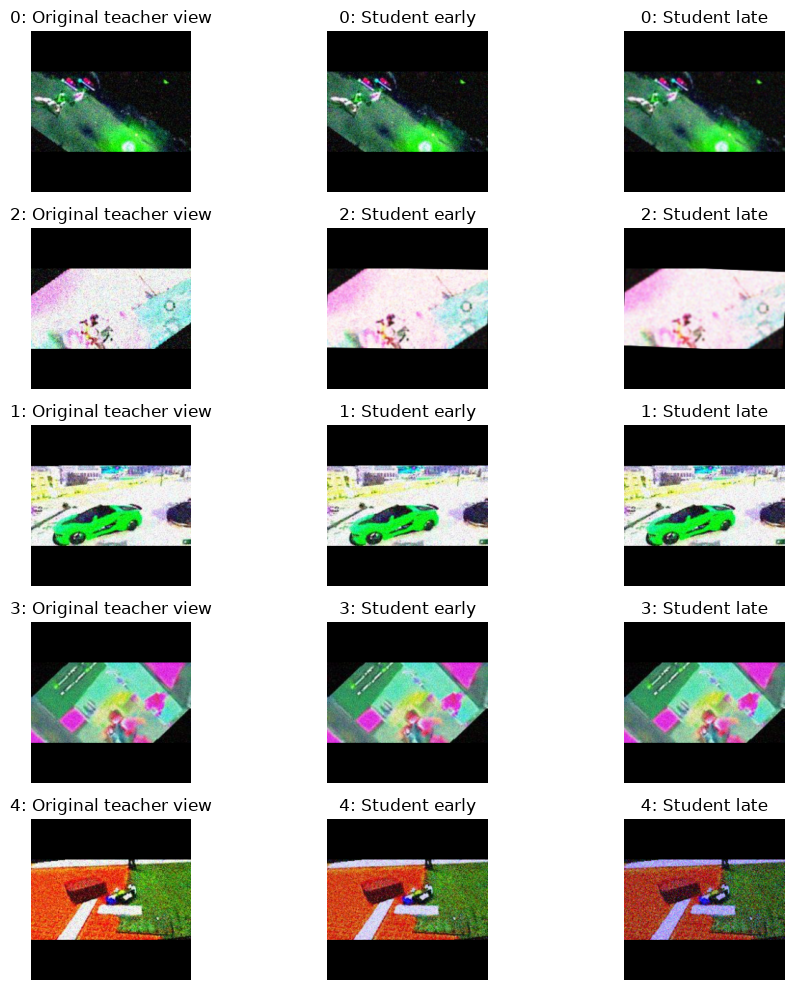

In [3]:
from Task4.models.image_curriculum_distillation import PairedImages
import matplotlib.pyplot as plt
from Task4.models.image_training import MEAN,STD
sample=groups.iloc[folds[0][0]].groupby('label').head(1).reset_index(drop=True)
ds=PairedImages(RAW,sample,training.RECIPES[NAME].epochs)
fig,axes=plt.subplots(len(ds),3,figsize=(10,2*len(ds)),squeeze=False)
for i in range(len(ds)):
    with torch.random.fork_rng():
        torch.manual_seed(123+i);ds.epoch=0;(early,original),label=ds[i]
        torch.manual_seed(123+i);ds.epoch=ds.epochs-1;(late,_),_=ds[i]
    for ax,x,title in zip(axes[i],[original,early,late],['Original teacher view','Student early','Student late']):
        rgb=(x*torch.tensor(STD)[:,None,None]+torch.tensor(MEAN)[:,None,None]).clamp(0,1)
        ax.imshow(rgb.permute(1,2,0));ax.set_title(f'{label}: {title}');ax.axis('off')
plt.tight_layout();plt.show()

## 3. ฝึกครบ5foldsและpaired validation
Teacher frozenทั้ง6epochs; ไม่มีการเลือกepochด้วยvalidation. แสดงเวลาepochจริงเพื่อประมาณเวลาที่เหลือ

In [5]:
oof={};scores=[];overlaps=[]
for fold in range(1,6):
    print('Teacher-student fold',fold,'/5',flush=True)
    parent=evaluation.references(ROOT,fold)[2]
    oof[fold]=training.run_fold(RAW,groups,folds,NAME,fold,OUT,BATCH_SIZE,NUM_WORKERS,init_path=parent)
    score,overlap=evaluation.compare(ROOT,RAW,groups,folds,OUT,fold,oof[fold])
    scores.append(score);overlaps.append(overlap)
    display(evaluation.summarize(score))
    history=json.loads((OUT/NAME/f'fold{fold}'/'history.json').read_text())
    display(pd.DataFrame(history)[['epoch','ce','kd','teacher_accepted_fraction','curriculum_progress','seconds']])
    seconds=np.mean([h['seconds'] for h in history[-3:]])
    print('Remaining CV TRAIN minutes, excluding validation:',round(seconds*training.RECIPES[NAME].epochs*(5-fold)/60,1))
all_scores=pd.concat(scores,ignore_index=True);all_overlap=pd.concat(overlaps,ignore_index=True)
all_scores.to_parquet(OUT/'development_scores.parquet',index=False)
all_overlap.to_parquet(OUT/'development_overlap.parquet',index=False)

Teacher-student fold 1 /5
fold1 epoch 2 / 6 loss 0.05731 seconds 237.1
fold1 epoch 3 / 6 loss 0.06022 seconds 251.4
fold1 epoch 4 / 6 loss 0.06564 seconds 254.7
fold1 epoch 5 / 6 loss 0.08222 seconds 240.7
fold1 epoch 6 / 6 loss 0.10008 seconds 236.9
stress fold1 gaussian_1
stress fold1 gaussian_2
stress fold1 speckle_1
stress fold1 speckle_2
stress fold1 blur_1
stress fold1 blur_2
stress fold1 jpeg_1
stress fold1 jpeg_2
stress fold1 dark_1
stress fold1 dark_2
stress fold1 compound_dark_noise
stress fold1 compound_color_noise
stress fold1 compound_rotation_dark
stress fold1 compound_bright_color
stress fold1 compound_dark_color_noise
stress fold1 compound_rotation_color_noise


suite,compound,original,single
procedure,,,
baseline,0.944725,0.986331,0.977201
blend25,0.944704,0.986732,0.977798
student,0.940710,0.981635,0.973795


,epoch,ce,kd,teacher_accepted_fraction,curriculum_progress,seconds
0,1,0.017694,0.084077,0.996988,0.0,248.620808
1,2,0.017483,0.079652,0.996988,0.2,237.089076
2,3,0.016709,0.087028,0.996988,0.4,251.436641
3,4,0.018880,0.093527,0.996988,0.6,254.681864
4,5,0.026420,0.111605,0.996988,0.8,240.749460
5,6,0.033484,0.133195,0.996988,1.0,236.920665


Remaining CV TRAIN minutes, excluding validation: 97.6
Teacher-student fold 2 /5


KeyboardInterrupt: 

## 4. Selectionและworst-condition evidence
เกณฑ์เดิม original≥−.001; family-balanced stress≥+.002และชนะ≥4/5; per-class≥−.01; worst-condition≥−.02. ไม่ลดเกณฑ์ตามผล; OOF reusedเป็นexploratory

In [ ]:
display(evaluation.summarize(all_scores))
selection=evaluation.select(all_scores)
validation.write_json(OUT/'development_selection.json',selection)
display(selection)
display(all_scores.groupby(['procedure','condition']).macro_F1.mean().unstack(0))
display(all_overlap[all_overlap.condition.eq('original')])

## 5. Audit veto — ไม่ปรับสูตรตามaudit

In [ ]:
audit_result={'passed':False,'reason':'Development did not select a candidate'}
if selection['chosen']!='baseline':
    audit_parts=[]
    for fold in range(1,6):
        score,_=evaluation.compare(ROOT,RAW,groups,folds,OUT,fold,oof[fold],phase='audit')
        audit_parts.append(score)
    audit_scores=pd.concat(audit_parts,ignore_index=True)
    audit_scores.to_parquet(OUT/'audit_scores.parquet',index=False)
    audit_result=evaluation.audit(audit_scores,selection['chosen'])
    display(evaluation.summarize(audit_scores))
validation.write_json(OUT/'audit_decision.json',audit_result)
display(audit_result)

## 6. Full refitและsave weights
ใช้full EfficientNetเดิมเป็นfrozen teacherและจุดเริ่มstudent หลังเลือกด้วยvalidationแล้ว. เซฟreadinessและmodel.pt ไม่เปิดTest

In [ ]:
full_path=None
if RUN_FULL_REFIT and selection['chosen']!='baseline' and audit_result['passed']:
    full_path=training.fit_fixed(RAW,groups,training.RECIPES[NAME],OUT/NAME/'full',BATCH_SIZE,NUM_WORKERS,init_path=ROOT/'Task4/models/results/backbone_diversity_v1/efficientnet_compound18/full/model.pt')
    validation.write_json(OUT/'ready_for_review.json',{
        'procedure':selection['chosen'],'student_model':str(full_path),'sha256':validation.sha(full_path),
        'test_used':False,'submission_created':False,
        'selection':selection,'audit':audit_result})
    print('Saved full model:',full_path)
else:
    print('No full refit: inspect development/audit results above. Existing baseline preserved.')